In [90]:
# note book for optimizing the weights per ring in order to match the surface to depth attenuation
# for a layered geology
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from scipy.optimize import minimize

ringPath = '/home/koley/CavityResults/AllTutOut/AttnKernel/'
obsPath = '/home/koley/pySeisNN1DFull/TERZ/attnModelNew.mat'
nRing = 8
ringBounds = np.array([[100, 200], [200, 500], [500, 1000], [1000, 2000],
                       [2000, 3000], [3000, 4000], [4000, 5000], [5000, 6000]])

# Optimization options (adjust after reviewing diagnostics)
fitBand = (3.0, 10.0)      # Hz
lambdaF = 0.1          # sequential frequency penalty on the 16 normalized force-power weights
maxiter = 5000
ftol = 1e-12

In [91]:
# Load only displacement PSD kernels: (nRing, nFreq, 6)
dispRingH, dispRingV = [], []
for m in range(0, nRing):
    h = loadmat(os.path.join(ringPath, f'dispRing{m}HForce.mat'))
    v = loadmat(os.path.join(ringPath, f'dispRing{m}VForce.mat'))
    if m == 0:
        freqOut = np.asarray(h['freqOut']).ravel().astype(float)
        zList = np.asarray(h['zList']).ravel()
    for mat in (h, v):
        assert np.allclose(freqOut, np.asarray(mat['freqOut']).ravel())
        assert np.allclose(zList, np.asarray(mat['zList']).ravel())
    dispRingH.append(np.asarray(h['dispAll']))
    dispRingV.append(np.asarray(v['dispAll']))
dispRingH, dispRingV = np.asarray(dispRingH), np.asarray(dispRingV)
assert dispRingH.shape == dispRingV.shape == (nRing, freqOut.size, 6)
assert np.all(np.diff(freqOut) > 0), 'freqOut must be ascending'
for name, arr in [('H', dispRingH), ('V', dispRingV)]:
    assert np.all(np.isfinite(arr)), f'{name}: nonfinite kernel values'
    assert np.max(np.abs(np.imag(arr))) < 1e-9 * max(1.0, np.max(np.abs(arr))), f'{name}: expected power kernels, not complex amplitudes'
    assert np.min(np.real(arr)) >= -1e-10 * max(1.0, np.max(np.abs(arr))), f'{name}: negative power kernel values'
dispRingH = np.maximum(np.real(dispRingH), 0.0)
dispRingV = np.maximum(np.real(dispRingV), 0.0)
print('H:', dispRingH.shape, 'V:', dispRingV.shape, 'frequency:', (freqOut[0], freqOut[-1]), 'depths:', zList)


H: (8, 41, 6) V: (8, 41, 6) frequency: (np.float64(2.0), np.float64(10.0)) depths: [  0. 250.]


In [92]:
# Observational columns follow the original notebook: [:,0]=frequency, [:,2]=median attenuation.
raw = loadmat(obsPath)
obsKeys = ['attnE', 'attnN', 'attnZ']
attnObs = np.column_stack([
    np.interp(freqOut, np.asarray(raw[k])[:, 0], np.asarray(raw[k])[:, 2],
              left=np.nan, right=np.nan)
    for k in obsKeys
])
fitMask = (freqOut >= fitBand[0]) & (freqOut <= fitBand[1])
fitMask &= np.all(np.isfinite(attnObs) & (attnObs > 0), axis=1)
# Do not fit frequencies where any surface/depth total kernel is identically zero.
fitMask &= np.all((dispRingH[:, :, :3].sum(axis=0) + dispRingV[:, :, :3].sum(axis=0)) > 0, axis=1)
fitMask &= np.all((dispRingH[:, :, 3:].sum(axis=0) + dispRingV[:, :, 3:].sum(axis=0)) > 0, axis=1)
print('Fitting', fitMask.sum(), 'of', len(freqOut), 'frequencies; band:', fitBand)
assert fitMask.any(), 'No valid frequencies: inspect observed frequency coverage and kernel PSDs'


Fitting 36 of 41 frequencies; band: (3.0, 10.0)


In [93]:
assert dispRingH.shape == dispRingV.shape

nRing, nFreq, _ = dispRingH.shape

assert dispRingH.shape[2] == 6
assert attnObs.shape == (nFreq, 3)
assert np.all(np.isfinite(attnObs))
assert np.all(attnObs > 0)

# ============================================================
# Outputs
# ============================================================

weightsReg = np.zeros((nFreq, nRing))
zetaReg    = np.zeros((nFreq, nRing))

attnFitReg = np.zeros((nFreq, 3))

misfitAttn  = np.zeros(nFreq)
misfitData  = np.zeros(nFreq)
misfitTotal = np.zeros(nFreq)

successReg = np.zeros(nFreq, dtype=bool)

# ============================================================
# Regularization strengths
# ============================================================

lambdaF     = 0.1
lambdaZetaF = 0.1
lambdaAttn  = 1.0

eps = 1e-30

# ============================================================
# Initial values
# ============================================================

wPrev = np.ones(nRing) / nRing
zetaPrev = 0.5 * np.ones(nRing)

# ============================================================
# Optimization over frequencies
# ============================================================

for jf in range(nFreq):

    # H-force power kernels
    PS_H = dispRingH[:, jf, 0:3]
    PD_H = dispRingH[:, jf, 3:6]

    # V-force power kernels
    PS_V = dispRingV[:, jf, 0:3]
    PD_V = dispRingV[:, jf, 3:6]

    Aobs = attnObs[jf, :]

    # ========================================================
    # Prediction from ring weights and H/V mixture
    # ========================================================

    def predict_attenuation(w, zeta):

        z = zeta[:, None]

        PS = (1.0 - z) * PS_H + z * PS_V
        PD = (1.0 - z) * PD_H + z * PD_V

        PSfit = np.real(w @ PS)
        PDfit = np.real(w @ PD)

        PSfit = np.maximum(PSfit, eps)
        PDfit = np.maximum(PDfit, eps)

        return np.sqrt(PSfit / PDfit)

    # ========================================================
    # Objective
    #
    # x[:nRing] -> ring weights
    # x[nRing:] -> H/V fractions for each ring
    # ========================================================

    def objective(x):

        w = x[:nRing]
        zeta = x[nRing:]

        # 1. Attenuation misfit
        Asim = predict_attenuation(w, zeta)

        rAttn = np.log(Asim / Aobs)
        chiAttn = np.sum(rAttn**2)

        # 2. Frequency smoothness of ring weights
        chiFreq = np.sum((w - wPrev)**2)

        # 3. Frequency smoothness of H/V fractions
        chiZetaFreq = np.sum((zeta - zetaPrev)**2)

        return (
            lambdaAttn * chiAttn
            + lambdaF * chiFreq
            + lambdaZetaF * chiZetaFreq
        )

    # ========================================================
    # Ring-weight normalization
    # ========================================================

    constraints = {
        "type": "eq",
        "fun": lambda x: np.sum(x[:nRing]) - 1.0
    }

    # ========================================================
    # Bounds
    # ========================================================

    bounds = (
        [(0.0, 1.0)] * nRing
        + [(0.0, 1.0)] * nRing
    )

    # ========================================================
    # Initial guess
    # ========================================================

    x0 = np.concatenate((wPrev, zetaPrev))

    # ========================================================
    # Optimize
    # ========================================================

    res = minimize(
        objective,
        x0,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={
            "maxiter": 5000,
            "ftol": 1e-12
        }
    )

    successReg[jf] = res.success

    if not res.success:
        print(
            f"Frequency index {jf}: "
            f"optimization warning: {res.message}"
        )

    # ========================================================
    # Extract solution
    # ========================================================

    w = res.x[:nRing]
    zeta = res.x[nRing:]

    weightsReg[jf, :] = w
    zetaReg[jf, :] = zeta

    # ========================================================
    # Reconstruct attenuation
    # ========================================================

    Asim = predict_attenuation(w, zeta)

    attnFitReg[jf, :] = Asim

    # ========================================================
    # Misfits
    # ========================================================

    rAttn = np.log(Asim / Aobs)

    misfitAttn[jf] = np.sum(rAttn**2)
    misfitData[jf] = lambdaAttn * misfitAttn[jf]
    misfitTotal[jf] = res.fun

    # ========================================================
    # Carry solution forward
    # ========================================================

    wPrev = w.copy()
    zetaPrev = zeta.copy()

print(
    f"Converged: {np.sum(successReg)}/{nFreq} frequencies"
)


Frequency index 0: optimization warning: Positive directional derivative for linesearch
Frequency index 1: optimization warning: Positive directional derivative for linesearch
Frequency index 2: optimization warning: Positive directional derivative for linesearch
Frequency index 3: optimization warning: Positive directional derivative for linesearch
Frequency index 4: optimization warning: Positive directional derivative for linesearch
Frequency index 5: optimization warning: Positive directional derivative for linesearch
Frequency index 6: optimization warning: Positive directional derivative for linesearch
Frequency index 8: optimization warning: Positive directional derivative for linesearch
Frequency index 10: optimization warning: Positive directional derivative for linesearch
Frequency index 11: optimization warning: Positive directional derivative for linesearch
Frequency index 12: optimization warning: Positive directional derivative for linesearch
Frequency index 13: optimizat

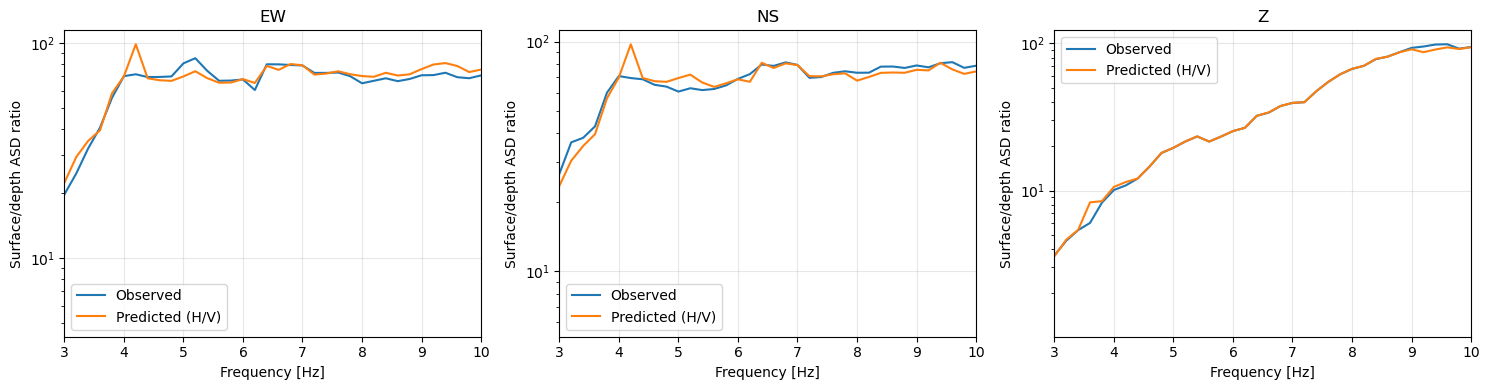

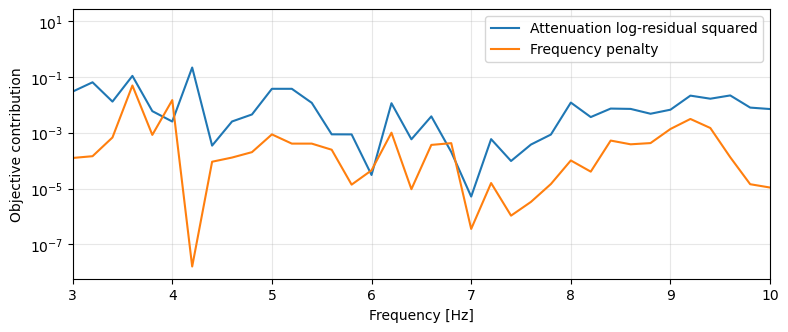

In [94]:
misfitSmooth = np.maximum(misfitTotal - misfitData, 0.0)
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for c, name in enumerate(['EW', 'NS', 'Z']):
    ax[c].semilogy(freqOut, attnObs[:, c], label='Observed')
    ax[c].semilogy(freqOut, attnFitReg[:, c], label='Predicted (H/V)')
    ax[c].set(xlim=fitBand, title=name, xlabel='Frequency [Hz]', ylabel='Surface/depth ASD ratio')
    ax[c].grid(alpha=0.3); ax[c].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogy(freqOut, misfitAttn, label='Attenuation log-residual squared')
ax.semilogy(freqOut, misfitSmooth, label='Frequency penalty')
ax.set(xlim=fitBand, xlabel='Frequency [Hz]', ylabel='Objective contribution')
ax.grid(alpha=0.3); ax.legend(); plt.show()


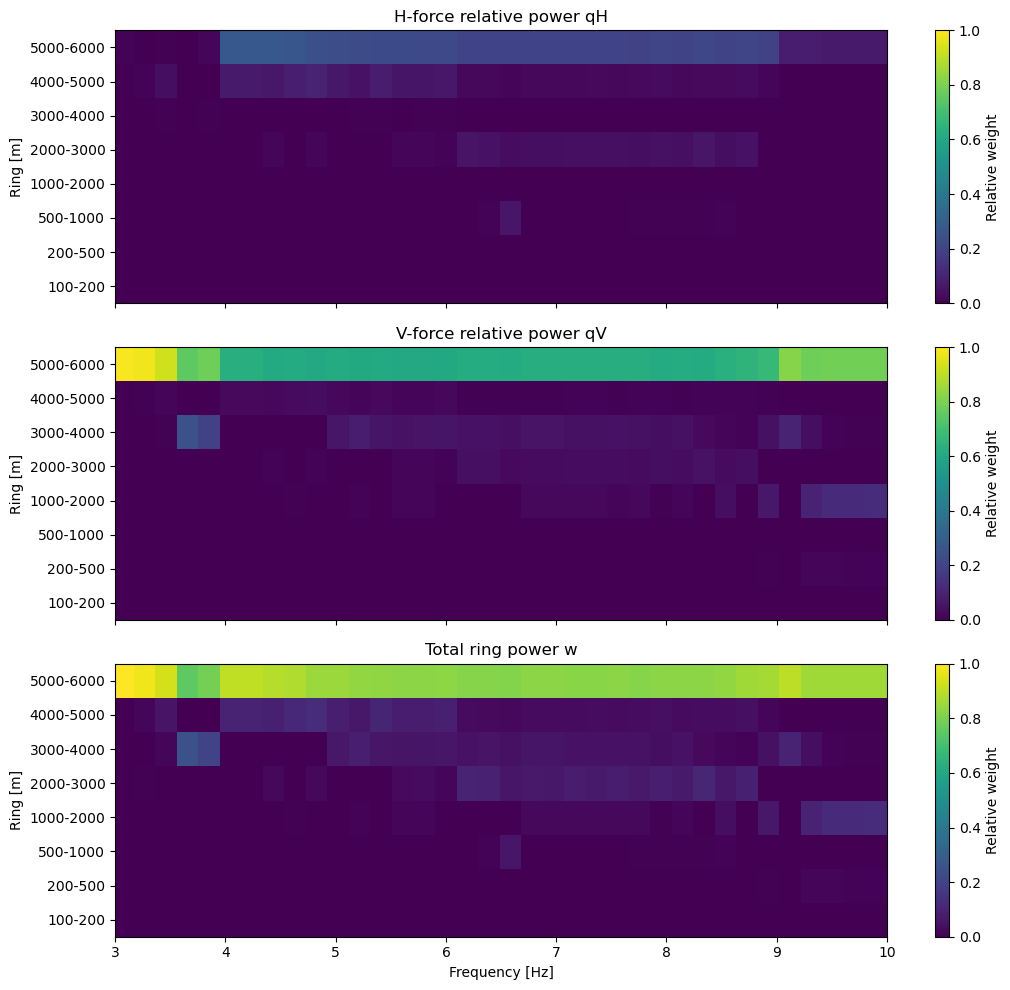

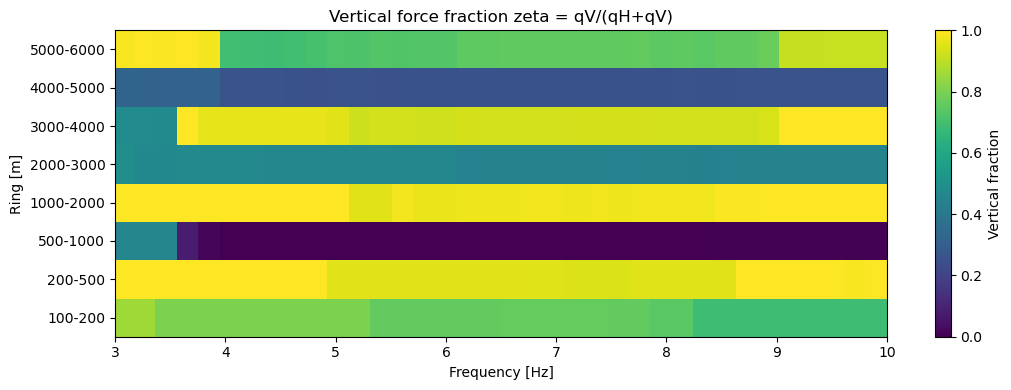

In [95]:
qHReg = weightsReg * (1.0 - zetaReg)
qVReg = weightsReg * zetaReg
ringLabels = [f'{a}-{b}' for a, b in ringBounds]
fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for a, values, label in zip(ax, [qHReg, qVReg, weightsReg],
                            ['H-force relative power qH', 'V-force relative power qV', 'Total ring power w']):
    pcm = a.imshow(values.T, aspect='auto', origin='lower', interpolation='nearest',
                   extent=[freqOut[0], freqOut[-1], 0, nRing], vmin=0, vmax=1)
    a.set(yticks=np.arange(nRing) + 0.5, yticklabels=ringLabels, ylabel='Ring [m]', title=label)
    fig.colorbar(pcm, ax=a, label='Relative weight')
ax[-1].set(xlabel='Frequency [Hz]', xlim=fitBand)
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(zetaReg.T, aspect='auto', origin='lower', interpolation='nearest',
               extent=[freqOut[0], freqOut[-1], 0, nRing], vmin=0, vmax=1)
ax.set(yticks=np.arange(nRing) + .5, yticklabels=ringLabels, xlim=fitBand,
       xlabel='Frequency [Hz]', ylabel='Ring [m]', title='Vertical force fraction zeta = qV/(qH+qV)')
fig.colorbar(im, ax=ax, label='Vertical fraction'); fig.tight_layout(); plt.show()


In [96]:
# Export results for later NN calculations; NaNs indicate omitted/undefined values.
outputPath = os.path.join(ringPath, 'opt_HV_ringWeights.mat')
savemat(outputPath, dict(freqOut=freqOut, ringBounds=ringBounds, fitMask=fitMask,
                         qHReg=qHReg, qVReg=qVReg, weightsReg=weightsReg, zetaReg=zetaReg,
                         attnObs=attnObs, attnFitReg=attnFitReg,
                         misfitAttn=misfitAttn, misfitSmooth=misfitSmooth,
                         misfitTotal=misfitTotal,
                         lambdaF=lambdaF, fitBand=np.asarray(fitBand)))
print('Saved:', outputPath)


Saved: /home/koley/CavityResults/AllTutOut/AttnKernel/opt_HV_ringWeights.mat


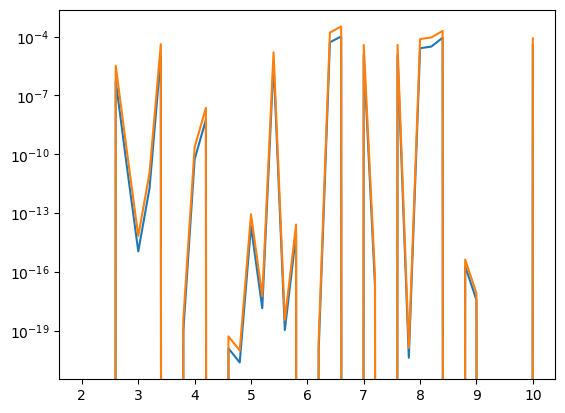

In [89]:
plt.semilogy(freqOut,qHReg[:,0])
plt.semilogy(freqOut,qVReg[:,0])
